# 5. Support Vector Regression (SVR)

## Lý thuyết & Nguyên lý

### 5.1. Siêu phẳng và dải lề sai số $\epsilon$ (Epsilon-Insensitive Tube)

SVR tìm một siêu phẳng $f(x) = w^\top x + b$ sao cho **càng nhiều điểm dữ liệu nằm trong một dải lề (tube) bán rộng $\epsilon$** xung quanh siêu phẳng càng tốt. Điểm nằm trong tube **không bị tính sai số** — đây là điểm khác biệt cốt lõi so với OLS của Linear Regression (mọi sai số đều bị tính bình phương):

$$L_\epsilon\big(y_i, \hat{y}_i\big) = \max\left(0,\; \left|y_i - \hat{y}_i\right| - \epsilon\right)$$

Bài toán tối ưu đầy đủ của SVR (epsilon-SVR):

$$\min_{w,\,b,\,\xi} \;\; \frac{1}{2}\|w\|^2 + C \sum_{i=1}^{n}\left(\xi_i + \xi_i^*\right)$$
$$\text{không gian hóa:}\quad \left|y_i - (w^\top x_i + b)\right| \le \epsilon + \xi_i, \quad \xi_i, \xi_i^* \ge 0$$

- $\dfrac{1}{2}\|w\|^2$: thành phần **cân bằng lề** (tìm siêu phẳng "mập" nhất, khoảng cách lớn nhất) — giống SVM phân loại.
- $C$: **trọng số đánh đổi** giữa độ phẳng của siêu phẳng và tổng sai số ngoài tube (soft margin).
- $\epsilon$: **bề rộng tube** — tăng $\epsilon$ ⇒ nhiều điểm được "tha" ⇒ mô hình đơn giản hóa (bias tăng, variance giảm).

Các điểm **nằm ngoài hoặc trên mép tube** gọi là **Support Vectors** — chỉ chúng quyết định mô hình; bỏ các điểm trong tube đi cũng không làm thay đổi kết quả.

### 5.2. Kernel Trick — xử lý dữ liệu phi tuyến

Khi dữ liệu không tuyến tính, SVR chiếu dữ liệu lên không gian đặc trưng cao hơn qua hàm kernel:

$$K(x, x') = \phi(x)^\top \phi(x')$$

Các kernel phổ biến:

- **Linear:** $K(x,x') = x^\top x'$
- **Polynomial:** $K(x,x') = (\gamma\, x^\top x' + r)^d$
- **RBF (Gaussian):** $K(x,x') = \exp\left(-\gamma \|x - x'\|^2\right)$ — mặc định, hoạt động tốt nhất trong hầu hết bài toán phi tuyến.

Siêu tham số $\gamma$ của RBF kiểm soát **phạm vi ảnh hưởng** của từng điểm huấn luyện: $\gamma$ lớn ⇒ từng điểm tạo "gò" nhọn riêng (dễ overfitting); $\gamma$ nhỏ ⇒ hiệu ứng lan tỏa mượt (dễ underfitting).

### 5.3. Lưu ý thực hành quan trọng

SVR tính khoảng cách giữa các điểm → **bắt buộc chuẩn hóa đặc trưng** (`StandardScaler`) trước khi huấn luyện, đặc biệt khi dùng kernel RBF.


Số lượng Support Vectors: 4 / 40 mẫu huấn luyện


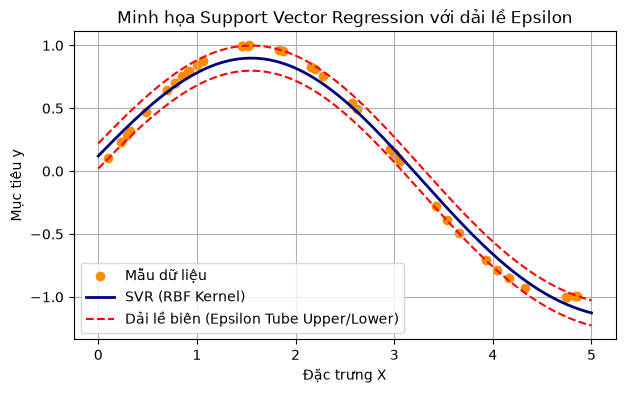

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVR

# 1. Dữ liệu: hàm sin + nhiễu
np.random.seed(42)
X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

# 2. Huấn luyện SVR với kernel RBF
svr_rbf = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1).fit(X, y)

# 3. Đường dự đoán và dải lề epsilon
X_test = np.linspace(0, 5, 500)[:, np.newaxis]
y_pred = svr_rbf.predict(X_test)

plt.figure(figsize=(7, 4))
plt.scatter(X, y, color='darkorange', label='Mẫu dữ liệu')
plt.plot(X_test, y_pred, color='navy', label='SVR (RBF Kernel)', linewidth=2)
plt.plot(
    X_test,
    y_pred + 0.1,
    'r--',
    label='Dải lề biên (Epsilon Tube Upper/Lower)',
)
plt.plot(X_test, y_pred - 0.1, 'r--')
plt.title('Minh họa Support Vector Regression với dải lề Epsilon')
plt.xlabel('Đặc trưng X')
plt.ylabel('Mục tiêu y')
plt.legend()
plt.grid(True)
plt.show()

print(f"Số lượng Support Vectors: {len(svr_rbf.support_)} / {len(X)} mẫu huấn luyện")


## Ý nghĩa của biểu đồ

- Đường **navy**: hàm suy luận của SVR — mượt và bám sát hàm sin nhờ kernel RBF.
- Hai đường **đứt đỏ**: mép trên/dưới của tube bán rộng $\epsilon = 0.1$. Các điểm nằm **giữa** hai đường đỏ không đóng góp sai số; các điểm nằm **ngoài** tube trở thành support vectors (bị đánh phạt bằng sai số tuyến tính $\xi$).
- Số support vectors thường chỉ bằng một phần nhỏ tập dữ liệu → mô hình "tóm tắt" dữ liệu bằng vài điểm then chốt, rất hữu ích khi dữ liệu lớn.

---

## Tổng quan mô hình

### Ưu điểm

- **Rất mạnh với dữ liệu phi tuyến** nhờ kernel trick, đặc biệt RBF.
- **Ổn định với điểm ngoại lai (outliers):** sai số ngoài tube bị đánh phạt tuyến tính (hinge loss), không phải bình phương như MSE → outlier không kéo lệch mô hình.
- **Chỉ phụ thuộc các support vectors** → mô hình "tóm tắt" dữ liệu bằng vài điểm then chốt, dự đoán nhanh trên dữ liệu huấn luyện.

### Nhược điểm

- **Không tự động chọn đặc trưng:** không xử lý được bài toán nhiều chiều thưa (curse of dimensionality tương tự các mô hình khoảng cách).
- **Tốn tài nguyên huấn luyện** với dữ liệu rất lớn — độ phức tạp khoảng $O(n^2)$ đến $O(n^3)$.
- **Nhiều siêu tham số phải tinh chỉnh:** $C$, $\gamma$, $\epsilon$ — cần GridSearchCV.
- **Phải chuẩn hóa dữ liệu** trước huấn luyện.
- Khó diễn giải mô hình nội tại (phụ thuộc các support vectors trong không gian chiếu).

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `C` | Đánh đổi giữa lề phẳng và sai số ngoài tube | `C` nhỏ → mô hình đơn giản, chịu sai số; `C` lớn → bám sát dữ liệu, dễ overfit |
| `gamma` | Phạm vi ảnh hưởng của từng điểm (RBF) | Thang log $[10^{-3}, 10^{1}]$; mặc định `scale` = $1/(p \cdot \text{Var}(X))$ |
| `epsilon` | Bán rộng tube — ngưỡng "không phạt" sai số | Thường 0.05–0.2 sau khi đã chuẩn hóa |
| `kernel` | linear / poly / rbf / sigmoid | RBF là mặc định tốt; dùng linear để giải thích/so sánh |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Mục tiêu ($y$) |
| :--- | :--- | :--- | :--- |
| **Tài chính** | Dự báo tín hiệu giao dịch | Chỉ báo kỹ thuật, khối lượng, biến động | Lợi nhuận kỳ vọng |
| **Công nghiệp** | Ước lượng tuổi thọ thiết bị | Nhiệt độ, áp suất, rung động chu kỳ | Số chu kỳ còn lại |
| **Y sinh** | Dự đoán liều thuốc tối ưu | Đặc trưng phân tử, nồng độ | Hiệu quả dược lý (liên tục) |
| **Môi trường** | Dự báo nồng độ ô nhiễm | Gió, nhiệt độ, giao thông, công xưởng | PM2.5 (µg/m³) |
| **Kỹ thuật** | Ước độ rung/xệ của cấu trúc | Tải trọng, vật liệu, chiều dài | Biến dạng (mm) |

### Mẹo thực hành

- Luôn dùng `Pipeline([('scaler', StandardScaler()), ('svr', SVR())])` + `GridSearchCV` quét `C`, `gamma` theo thang log.
- So sánh với `GradientBoostingRegressor` trên dữ liệu bảng thật — GBR thường thắng SVR nếu dữ liệu nhiều đặc trưng rời rạc/categorical.


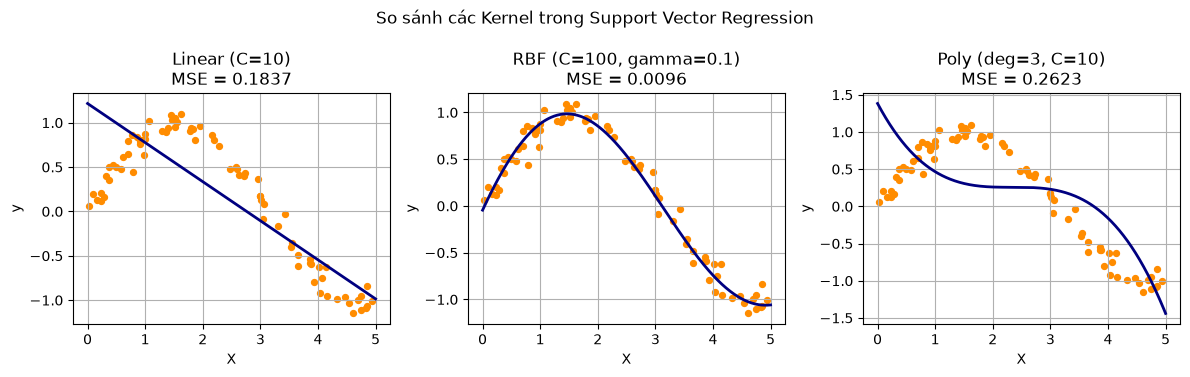

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# 1. Dữ liệu: hàm sin + nhiễu
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 80)
X_test = np.linspace(0, 5, 500)[:, np.newaxis]

# 2. So sánh 3 kernel khác nhau (đều có chuẩn hóa trước)
models = {
    'Linear (C=10)': make_pipeline(StandardScaler(), SVR(kernel='linear', C=10)),
    'RBF (C=100, gamma=0.1)': make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, gamma=0.1)),
    'Poly (deg=3, C=10)': make_pipeline(StandardScaler(), SVR(kernel='poly', degree=3, C=10)),
}

plt.figure(figsize=(12, 3.8))
for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y, model.predict(X))

    plt.subplot(1, 3, i)
    plt.scatter(X, y, s=18, color='darkorange')
    plt.plot(X_test, y_pred, color='navy', linewidth=2)
    plt.title(f'{name}\nMSE = {mse:.4f}')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.grid(True)

plt.suptitle('So sánh các Kernel trong Support Vector Regression')
plt.tight_layout()
plt.show()


## Giải thích kết quả

- **Linear:** đường thẳng — underfitting trầm trọng với dữ liệu sin (không bắt được phi tuyến).
- **RBF:** bám sát hàm sin, MSE thấp nhất trong ba kernel ở ví dụ này — minh chứng sức mạnh của kernel trick.
- **Polynomial:** có thể uốn theo dữ liệu, nhưng ngoài miền huấn luyện thường **phóng đại mạnh** (đa thức bùng nổ) — kém ổn định hơn RBF khi ngoại suy.

→ **Kinh nghiệm thực hành:** trên dữ liệu phi tuyến không rõ hình dạng, bắt đầu bằng **RBF + GridSearchCV** cho `(C, gamma)`.
